# 👁️ Konvolyusiya Şəbəkələrinə (CNN) Giriş: Kompüter Görməsinin Zirvəsi

Bu notebookda yenidən klassik **MNIST** əlyazma rəqəmləri bazasından istifadə edəcəyik. Lakin bu dəfə adi çoxqatlı perseptron (MLP) əvəzinə, vizual təsvirlərin analizi üçün xüsusi olaraq yaradılmış **CNN (Convolutional Neural Network - Konvolyusiya Neyron Şəbəkələri)** arxitekturasını quracağıq.

---

### 🤔 Niyə Şəkillər Üçün Adi MLP Yetmir və CNN Lazımdır?

1. **Məkan Əlaqələrinin İtməsi (Spatial Relationships):**  
   Əvvəlki dərsdə $28 \times 28$ ölçülü şəkli 784 elementli düz bir xəttə çevirmişdik (**Flatten**). Nəticədə qonşu piksellərin bir-biri ilə olan həndəsi əlaqəsi (xətlər, bucaqlar, qövslər) məhv olurdu.
2. **Sürüşməyə Həssaslıq (Translation Invariance Yoxluğu):**  
   Adi şəbəkədə əgər rəqəm bir qədər sola və ya sağa çəkilərsə, tamamilə fərqli giriş neyronları aktivləşir və model çaş-baş qalır.
3. **CNN-in Gücü:**  
   CNN şəkli düzləşdirmir! O, şəklin 2D təbii formasını saxlayır və üzərində kiçik filtrlər (kernel) gəzdirərək lokal xüsusiyyətləri aşkarlayır. Rəqəm şəklin harasında olursa olsun, eyni dəqiqliklə tanınır!

Əvvəlki MLP modelimizlə **~97-98%** dəqiqlik almışdıq. İndi isə CNN ilə bu göstəricini **99% və daha yuxarı** səviyyəyə qaldıracağıq!

İlk növbədə Keras-ın CNN üçün nəzərdə tutulmuş xüsusi qatlarını layihəyə daxil edirik:

In [15]:
import tensorflow
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv2D, MaxPooling2D, Flatten
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras import backend as K

import matplotlib.pyplot as plt
import numpy as np

## 📦 MNIST Verilənlər Bazasının Yüklənməsi

Əvvəlki dərslərdə olduğu kimi, 60,000 təlim və 10,000 test nümunəsini yükləyirik:

In [2]:
(mnist_train_images, mnist_train_labels), (mnist_test_images, mnist_test_labels) = mnist.load_data()

print(mnist_train_images.shape)
print(mnist_test_images.shape)
print(mnist_train_labels.shape)
print(mnist_test_labels.shape)

(60000, 28, 28)
(10000, 28, 28)
(60000,)
(10000,)


## 🛠️ Verilənlərin Formalaşdırılması (Reshaping): CNN Formatı

Bura olduqca vacib bir məqamdır!

Adi neyron şəbəkəsində şəkli 784 elementli 1-ölçülü vektora çevirirdik. **CNN isə şəkli ikiölçülü (2D) matris və rəng kanalı ilə birlikdə tələb edir:**
$$\text{Ölçü: } [Nümunə \text{ sayı}, \text{Hündürlük}, \text{En}, \text{Rəng Kanalı}]$$

* **Kanal sayı nədir?**
  * Ağ-qara (Grayscale) şəkillərdə rəng yoxdur, yalnız parlaqlıq var $\to$ **1 kanal** (`28, 28, 1`).
  * Əgər rəngli (RGB) şəkillər olsaydı $\to$ **3 kanal** (Qırmızı, Yaşıl, Mavi) olardı (`28, 28, 3`).

* **`channels_first` vs `channels_last`:**  
  Keras bəzi arxa mühərriklərdə kanalı əvvələ qoyur (`1, 28, 28`), əksər hallarda isə axıra (`28, 28, 1`). Aşağıdakı kod hər iki halı avtomatik yoxlayır və uyğunlaşdırır.

Həmçinin pikselləri 255-ə bölərək `[0.0, 1.0]` aralığına normallaşdırırıq:

In [5]:
# Keras konfiqurasiyasına görə kanalın yerini təyin edirik
if K.image_data_format() == 'channels_first':
    train_images = mnist_train_images.reshape(mnist_train_images.shape[0], 1, 28, 28)
    test_images = mnist_test_images.reshape(mnist_test_images.shape[0], 1, 28, 28)
    input_shape = (1, 28, 28)
else:
    # Standart TensorFlow formatı: (Hündürlük, En, Kanal) -> (28, 28, 1)
    train_images = mnist_train_images.reshape(mnist_train_images.shape[0], 28, 28, 1)
    test_images = mnist_test_images.reshape(mnist_test_images.shape[0], 28, 28, 1)
    input_shape = (28, 28, 1)

# Pikselləri float32 onluq kəsr tipinə çeviririk
train_images = train_images.astype('float32')
test_images = test_images.astype('float32')

# [0, 255] parlaqlıq qiymətlərini [0.0, 1.0] aralığına normallaşdırırıq
train_images /= 255
test_images /= 255

## 🎯 Etiketlərin "One-Hot" Formatına Çevrilməsi

Hədəf rəqəmləri (0-9) 10 ölçülü ikili (binary) vektor şəklində kodlaşdırırıq:
* Məsələn, rəqəm $3 \to [0, 0, 0, 1, 0, 0, 0, 0, 0, 0]$ (yalnız 3-cü indeks $1$-dir):

In [6]:
# Rəqəm etiketlərini 10 ölçülü one-hot vektorlarına çeviririk
train_labels = tensorflow.keras.utils.to_categorical(mnist_train_labels, 10)
test_labels = tensorflow.keras.utils.to_categorical(mnist_test_labels, 10)

Verilənlərin düzgün yükləndiyini və one-hot formatını vizual olaraq yoxlamaq üçün təlim dəstindən bir nümunə şəkil çəkdirək:

One-hot etiket: [0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]


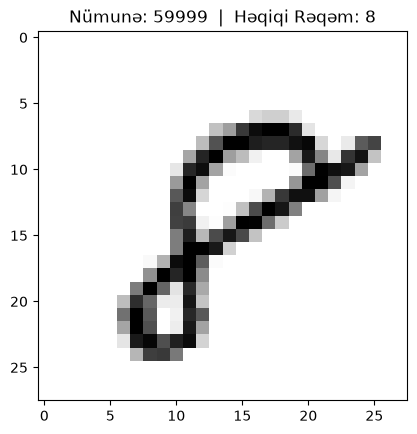

In [9]:
def display_sample(num):
    # Bu nümunənin one-hot vektorunu çap edirik
    print("One-hot etiket:", train_labels[num])  
    # Ən yüksək indeks vasitəsilə həqiqi rəqəmi tapırıq
    label = train_labels[num].argmax(axis=0)
    # Şəkli ekranda 28x28 olaraq nümayiş etdiririk
    image = train_images[num].reshape([28, 28])
    plt.title('Nümunə: %d  |  Həqiqi Rəqəm: %d' % (num, label))
    plt.imshow(image, cmap=plt.get_cmap('gray_r'))
    plt.show()

# 60,000-ci nümunəni nümayiş etdiririk
display_sample(59999)

## 🏗️ CNN Arxitekturasının Qurulması: Addım-Addım İzah

İndi məsələnin ən maraqlı və vacib hissəsinə gəlirik. Konvolyusiya Şəbəkəmizi qat-qat inşa edirik:

```
[GİRİŞ: 28x28x1]
      ⬇️
[Conv2D: 32 filtr (3x3)]  -> Sadə xüsusiyyətlər (şaquli/üfüqi xətlər, kənarlar)
      ⬇️
[Conv2D: 64 filtr (3x3)]  -> Mürəkkəb formalar (bucaqlar, dairələr, qövslər)
      ⬇️
[MaxPooling2D: (2x2)]     -> Ölçünü yarıya endirir (14x14) və parametrləri 75% azaldır
      ⬇️
[Dropout: 0.25]           -> Əzbərləmənin (Overfitting) qarşısını almaq üçün 25% neyronu söndürür
      ⬇️
[Flatten]                 -> 2D xəritələri son qərar üçün 1D düz vektora çevirir
      ⬇️
[Dense: 128 neyron]       -> Xüsusiyyətləri birləşdirən tam əlaqəli beyin mərkəzi
      ⬇️
[Dropout: 0.50]           -> Zəif əlaqələri təmizləmək üçün 50% neyronu söndürür
      ⬇️
[Dense: 10 + Softmax]     -> 0-9 rəqəmləri üçün ehtimal paylanması
```

### 🔍 Qatların İş Prinsipləri:
1. **`Conv2D(32, kernel_size=(3, 3))`:** Şəklin üzərində 32 fərqli kiçik $3 \times 3$ pəncərə gəzərək xüsusiyyət xəritələri (*feature maps*) yaradır.
2. **`Conv2D(64, kernel_size=(3, 3))`:** Birinci qatın tapdığı sadə xətlərdən daha mürəkkəb həndəsi formalar çıxarır.
3. **`MaxPooling2D(pool_size=(2, 2))`:** Hər $2 \times 2$ blokdan ən böyük ədədi götürür. Ölçünü kiçildir, hesablama yükünü azaldır və rəqəmin kiçik əyilmələrinə qarşı dayanıqlılıq (*Invariance*) yaradır.
4. **`Dropout`:** Neyronların təsadüfi bir hissəsini hər addımda müvəqqəti "söndürür". Beləliklə, şəbəkə tək bir neyrona güvənmir və ümumiləşdirmə qabiliyyəti güclənir.

In [10]:
# Ardıcıl CNN modelini qururuq
model = Sequential()

# 1. Konvolyusiya qatı: 32 filtr (3x3 ölçülü) və ReLU aktivasiyası
model.add(Conv2D(32, kernel_size=(3, 3),
                 activation='relu',
                 input_shape=input_shape))

# 2. İkinci Konvolyusiya qatı: 64 filtr (3x3 ölçülü)
model.add(Conv2D(64, (3, 3), activation='relu'))

# 3. Max Pooling: hər 2x2 piksellik pəncərədən ən böyük dəyəri seçərək ölçünü kiçildir
model.add(MaxPooling2D(pool_size=(2, 2)))

# 4. Dropout: Həddindən artıq uyğunlaşmanın (Overfitting) qarşısını almaq üçün 25% neyronu söndürürük
model.add(Dropout(0.25))

# 5. Düzləşdirmə: 2D xəritələri tam əlaqəli (Dense) qat üçün 1-ölçülü vektora çeviririk
model.add(Flatten())

# 6. Gizli tam əlaqəli qat: 128 neyron və ReLU aktivasiyası
model.add(Dense(128, activation='relu'))

# 7. İkinci Dropout: 50% neyronu təsadüfi söndürürük
model.add(Dropout(0.5))

# 8. Çıxış qatı: 0-dan 9-a qədər 10 sinif və Softmax ehtimal aktivasiyası
model.add(Dense(10, activation='softmax'))

c:\Users\tarlan.cabiyev\AppData\Local\anaconda3\envs\tf_env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## 📋 Modelin Arxitektura Xülasəsi: `model.summary()`

Modelimizin qatlarının ardıcıllığına, çıxış ölçülərinə və ümumi öyrənilən parametrlərin sayına baxaq:

In [11]:
# Modelin daxili strukturunu və parametrlər sayını ekrana çıxarırıq
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,199,882 (4.58 MB)

 Trainable params: 1,199,882 (4.58 MB)

 Non-trainable params: 0 (0.00 B)

Gördüyünüz kimi, modeldə **təxminən 1.2 milyon öyrənilən parametr** var! Bu parametrlərin böyük əksəriyyəti `Flatten` qatından `Dense(128)` qatına keçid zamanı formalaşır.

---

## ⚙️ Modelin Kompilyasiyası: Optimizator və İtki Funksiyası

* **İtki Funksiyası (`loss='categorical_crossentropy'`):** Çoxsinifli təsnifat üçün one-hot formatına uyğun ən optimal itki funksiyası.
* **Optimizator (`optimizer='adam'`):** Müasir dərin öyrənmənin ən populyar və güclü optimizatoru olan **Adam (Adaptive Moment Estimation)**. O, həm Momentum (təcil), həm də RMSprop-un adaptiv öyrənmə sürəti üstünlüklərini birləşdirir.
* **Metrika (`metrics=['accuracy']`):** Dəqiqlik faizi.

In [12]:
# Modeli itki funksiyası, Adam optimizatoru və dəqiqlik metrikası ilə təchiz edirik
model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

## 🏋️ Modelin Təlim Edilməsi: `model.fit()`

Modeli **10 epoch** ərzində **32-lik partiyalarla (batch_size=32)** təlim edirik.

> ⚠️ **Hesablama Gücü və Vaxt Haqqında Xəbərdarlıq:**  
> CNN qatlarında milyonlarla konvolyusiya (matris sürüşdürmə və vurma) əməliyyatı aparıldığı üçün əgər kompüterinizdə güclü qrafik kartı (GPU) yoxdursa və proses adi CPU üzərində gedirsə, hər bir epoch bir neçə dəqiqə vaxt apara bilər.  
> Təlim zamanı kompüterinizin prosessoru tam gücü ilə işləyəcək.

In [13]:
# Modeli 10 dövr (epoch) ərzində təlim edirik
history = model.fit(train_images, train_labels,
                    batch_size=32,
                    epochs=10,
                    verbose=2,
                    validation_data=(test_images, test_labels))

Epoch 1/10
1875/1875 - 15s - 8ms/step - accuracy: 0.9446 - loss: 0.1832 - val_accuracy: 0.9832 - val_loss: 0.0516
Epoch 2/10
1875/1875 - 14s - 8ms/step - accuracy: 0.9771 - loss: 0.0783 - val_accuracy: 0.9876 - val_loss: 0.0407
Epoch 3/10
1875/1875 - 17s - 9ms/step - accuracy: 0.9815 - loss: 0.0611 - val_accuracy: 0.9896 - val_loss: 0.0298
Epoch 4/10
1875/1875 - 19s - 10ms/step - accuracy: 0.9846 - loss: 0.0503 - val_accuracy: 0.9913 - val_loss: 0.0262
Epoch 5/10
1875/1875 - 19s - 10ms/step - accuracy: 0.9869 - loss: 0.0415 - val_accuracy: 0.9908 - val_loss: 0.0285
Epoch 6/10
1875/1875 - 19s - 10ms/step - accuracy: 0.9885 - loss: 0.0365 - val_accuracy: 0.9917 - val_loss: 0.0290
Epoch 7/10
1875/1875 - 18s - 10ms/step - accuracy: 0.9901 - loss: 0.0324 - val_accuracy: 0.9922 - val_loss: 0.0287
Epoch 8/10
1875/1875 - 18s - 10ms/step - accuracy: 0.9906 - loss: 0.0283 - val_accuracy: 0.9927 - val_loss: 0.0274
Epoch 9/10
1875/1875 - 19s - 10ms/step - accuracy: 0.9920 - loss: 0.0256 - val_accu

## 🏆 Yekun Nəticə və Qiymətləndirmə: `model.evaluate()`

Zəhmətimizə dəydimi? Gəlin modelin heç vaxt görmədiyi **10,000 test şəkli** üzərində rəsmi dəqiqliyini və itkisini ölçək:

In [14]:
# Test dəsti üzərində modelin dəqiqliyini qiymətləndiririk
score = model.evaluate(test_images, test_labels, verbose=0)
print('Test İtkisi (Loss): %.4f' % score[0])
print('Test Dəqiqliyi (Accuracy): %.2f%%' % (score[1] * 100))

Test İtkisi (Loss): 0.0263
Test Dəqiqliyi (Accuracy): 99.28%


## 🌟 Möhtəşəm Nəticə: 99%-dən Yüksək Dəqiqlik!

Test dəstində dəqiqlik **99%-i keçdi!** (10,000 şəkildən 9,920-dən çoxu tamamilə düzgün tapıldı).

Hətta diqqət yetirsəniz, cəmi 4-5 epoch sonra model artıq bu yüksək səviyyəyə çatmışdı. 

### 💡 Bu Niyə Vacibdir?
Adi perseptron (MLP) ilə 97-98% almışdıq, amma CNN ilə 99.2%+ aldıq. Fərq ilk baxışda kiçik görünsə də, xəta edən şəkillərin sayı **300-dən 80-ə düşdü (xətalar təxminən 4 dəfə azaldı!)**.  
Pilotsuz avtomobillər (*Self-driving cars*), tibbi diaqnostika (rentgen və MRT analizi) kimi həyati əhəmiyyətli sahələrdə dəqiqliyin hər 0.1%-i insan həyatını xilas edə bilər!

---

## 🎯 Yekun Xülasə: Nələri Öyrəndik?

1. **CNN Kompüter Görməsinin Standartıdır:** Şəklin ikiölçülü məkan formasını saxlayaraq xətləri, kənarları və formaları filtrlərlə aşkarlayır.
2. **Konvolyusiya + Pooling Gücü:** Konvolyusiya xüsusiyyəti tapır, Max Pooling isə ölçünü kiçildib modeli sürüşmələrə qarşı dayanıqlı edir.
3. **Dropout Effekti:** Mürəkkəb CNN şəbəkələrində əzbərləmənin (*Overfitting*) qarşısını almaqda əvəzsizdir.
4. **99%+ Dəqiqlik:** Sadə MLP ilə müqayisədə xəta faizini dəfələrlə azaltdıq! 🚀

In [16]:
# Səhv təxmin edilən şəkilləri tapmaq və araşdırmaq üçün kod bloku:
# İstəsəniz bu bloku işə salaraq modelin hansı rəqəmlərdə yanıldığını görə bilərsiniz:

errors = 0
for i in range(500):
    test_img = test_images[i:i+1]
    pred = model.predict(test_img, verbose=0).argmax()
    actual = test_labels[i].argmax()
    if pred != actual:
        errors += 1
        print(f"Şəkil #{i} -> Həqiqi: {actual} | Modelin Təxmini: {pred}")

print(f"İlk 500 şəkildə cəmi {errors} səhv tapıldı.")

Şəkil #340 -> Həqiqi: 5 | Modelin Təxmini: 3
Şəkil #445 -> Həqiqi: 6 | Modelin Təxmini: 0
İlk 500 şəkildə cəmi 2 səhv tapıldı.
